In [0]:
%pip install tensorflow
import numpy as np
import pandas as pd
import tensorflow as tf

tf.random.set_seed(42)

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
@tf.function
def hill_tf(ad_stock, alpha, gamma):

    ad_stock = tf.cast(ad_stock, tf.float32)
    alpha = tf.cast(alpha, tf.float32)
    gamma = tf.cast(gamma, tf.float32)

    ad_stock = tf.maximum(ad_stock, 0.0)

    ad_stock_alpha = tf.pow(ad_stock, alpha)
    gamma_alpha = tf.pow(gamma, alpha)

    return (
        ad_stock_alpha /
        (ad_stock_alpha + gamma_alpha + 1e-8)
    )

In [0]:
@tf.function
def adstock_tf(ad_stock, decay):

    ad_stock = tf.cast(ad_stock, tf.float32)
    decay = tf.cast(decay, tf.float32)

    def step(previous_effect, current_spend):
        return current_spend + decay * previous_effect

    first = ad_stock[0]

    rest = tf.scan(
        step,
        ad_stock[1:],
        initializer=first
    )

    return tf.concat(
        [
            tf.reshape(first, [1]),
            rest
        ],
        axis=0
    )

In [0]:
def make_data(n_weeks=156, seed=42):

    # Reproducible random generator
    rng = np.random.default_rng(seed)

    # 1. DATE AND SEASONALITY
    

    weeks = pd.date_range(
        "2023-01-02",
        periods=n_weeks,
        freq="W-MON"
    )

    woy = (
        weeks.isocalendar()
        .week
        .to_numpy()
        .astype(float)
    )

    season = (
        1.0
        + 0.35 * np.exp(
            -((woy - 47) ** 2) / (2 * 4.0 ** 2)
        )
        + 0.12 * np.exp(
            -((woy - 4) ** 2) / (2 * 3.0 ** 2)
        )
    )

    # General business growth
    trend = np.linspace(1.0, 1.18, n_weeks)

    
    # 2. EXPECTED MARKETING SPENDING
    

    expected_spends = {
        "TV": 900 * season,
        "Paid Search": 500 * season,
        "Social": 350 * season,
        "Display": 250 * season,
        "Email": 90 * season
    }

    # 3. RANDOMIZED MARKETING SPENDING
    

    def spend(base, vol):

        randomized_spend = (
            base * season *
            (1 + rng.normal(0, vol, n_weeks))
        )

        return np.clip(
            randomized_spend,
            base * 0.2,
            None
        )

    spends = {
        "TV": spend(900, 0.25),
        "Paid Search": spend(500, 0.30),
        "Social": spend(350, 0.35),
        "Display": spend(250, 0.35),
        "Email": spend(90, 0.40)
    }

    # 4. PRICE AND PROMOTION

    price = 1999 + rng.normal(0, 40, n_weeks)

    promo = (
        np.clip(rng.random(n_weeks) - 0.6, 0, None)
        * 0.9
    )

    price_eff = price * (1 - promo)

    # 5. GROUND-TRUTH CHANNEL PARAMETERS

    truth = {

        "TV": (
            0.65,   # decay
            1.3,    # alpha
            1400,   # gamma
            4200    # beta
        ),

        "Paid Search": (
            0.30,
            1.1,
            700,
            3800
        ),

        "Social": (
            0.45,
            1.2,
            520,
            2600
        ),

        "Display": (
            0.50,
            1.4,
            430,
            1500
        ),

        "Email": (
            0.20,
            1.0,
            120,
            1100
        )
    }

    # 6. FUNCTION TO CALCULATE AD CONTRIBUTION

    def calculate_media_contribution(spend_data):

        total_media = tf.zeros(
            shape=(n_weeks,),
            dtype=tf.float32
        )

        channel_contributions = {}

        for channel, (
            decay,
            alpha,
            gamma,
            beta
        ) in truth.items():

            spend_tf = tf.convert_to_tensor(
                spend_data[channel],
                dtype=tf.float32
            )

            # Step 1: Adstock
            adstocked = adstock_tf(
                spend_tf,
                decay
            )

            # Step 2: Hill saturation
            saturated = hill_tf(
                adstocked,
                alpha,
                gamma
            )

            # Step 3: Advertising contribution
            channel_effect = beta * saturated

            channel_contributions[channel] = (
                channel_effect.numpy()
            )

            total_media = total_media + channel_effect

        return (
            total_media.numpy(),
            channel_contributions
        )

    # 7. BASELINE, PRICE AND PROMOTION EFFECTS

    base = 26000.0

    base_sales = (
        base * trend * season
    )

    price_contrib = (
        -9.5 * (price_eff - 1999.0)
    )

    promo_contrib = (
        5200 * promo
    )

    # 8. TABLE 1: BEFORE RANDOMNESS

    expected_media, expected_channel_effects = (
        calculate_media_contribution(expected_spends)
    )

    expected_sales = (
        base_sales
        + expected_media
        + price_contrib
        + promo_contrib
    )

    before_df = pd.DataFrame({

        "week": weeks,

        "tv": expected_spends["TV"],
        "search": expected_spends["Paid Search"],
        "social": expected_spends["Social"],
        "display": expected_spends["Display"],
        "email": expected_spends["Email"],

        "total_ad_spend": (
            expected_spends["TV"]
            + expected_spends["Paid Search"]
            + expected_spends["Social"]
            + expected_spends["Display"]
            + expected_spends["Email"]
        ),
        "price": price,
        "promo": promo,
        "season_idx": season,
        "trend": trend,

        "baseline_sales": base_sales,
        "price_contribution": price_contrib,
        "promo_contribution": promo_contrib,

        "ad_sales_contribution": expected_media,

        "expected_sales": expected_sales
    })


    # 9. TABLE 2: AFTER RANDOMNESS

    randomized_media, randomized_channel_effects = (
        calculate_media_contribution(spends)
    )

    randomized_expected_sales = (
        base_sales
        + randomized_media
        + price_contrib
        + promo_contrib
    )

    # Add sales noise
    sales_noise = rng.normal(
        0,
        randomized_expected_sales * 0.03,
        n_weeks
    )

    sales = np.round(
        np.clip(
            randomized_expected_sales + sales_noise,
            0,
            None
        )
    ).astype(int)

    after_df = pd.DataFrame({

        "week": weeks,

        "tv": spends["TV"],
        "search": spends["Paid Search"],
        "social": spends["Social"],
        "display": spends["Display"],
        "email": spends["Email"],

        "total_ad_spend": (
            spends["TV"]
            + spends["Paid Search"]
            + spends["Social"]
            + spends["Display"]
            + spends["Email"]
        ),
        "price": price,
        "promo": promo,
        "season_idx": season,
        "trend": trend,

        "baseline_sales": base_sales,
        "price_contribution": price_contrib,
        "promo_contribution": promo_contrib,

        "ad_sales_contribution": randomized_media,

        "expected_sales_before_noise": randomized_expected_sales,

        "sales_noise": sales_noise,

        "sales_units": sales
    })

    # 10. TABLE 3: FINAL TRAINING DATASET
    

    training_df = pd.DataFrame({

        "week": weeks,

        "tv": spends["TV"],
        "search": spends["Paid Search"],
        "social": spends["Social"],
        "display": spends["Display"],
        "email": spends["Email"],

        "price": price,
        "promo": promo,

        "season_idx": season,
        "trend": trend,

        "sales_units": sales
    })

    # Format dates
    for table in [before_df, after_df, training_df]:

        table["week"] = (
            table["week"].dt.strftime("%Y-%m-%d")
        )

    return (
        before_df.round(2),
        after_df.round(2),
        training_df,
        truth
    )


# Generate all three tables
before_df, after_df, training_df, truth = make_data()

# Keep df as the final training dataset
df = training_df.copy()

In [0]:
print("TABLE 1: EXPECTED VALUES BEFORE RANDOMNESS")

display(before_df)

TABLE 1: EXPECTED VALUES BEFORE RANDOMNESS


week,tv,search,social,display,email,total_ad_spend,price,promo,season_idx,trend,baseline_sales,price_contribution,promo_contribution,ad_sales_contribution,expected_sales
2023-01-02,965.51,536.39,375.47,268.2,96.55,2242.12,1996.95,0.0,1.07,1.0,27892.38,19.45,0.0,5276.65,33188.48
2023-01-09,986.48,548.04,383.63,274.02,98.65,2290.82,1995.81,0.0,1.1,1.0,28531.4,30.3,0.0,6822.23,35383.92
2023-01-16,1002.16,556.76,389.73,278.38,100.22,2327.25,2070.9,0.0,1.11,1.0,29018.64,-683.07,0.0,7437.8,35773.37
2023-01-23,1008.0,560.0,392.0,280.0,100.8,2340.8,2034.77,0.0,1.12,1.0,29221.45,-339.8,0.0,7723.74,36605.39
2023-01-30,1002.16,556.76,389.73,278.38,100.22,2327.25,1999.46,0.29,1.11,1.0,29085.88,5412.29,1482.85,7852.83,43833.85
2023-02-06,986.48,548.04,383.63,274.02,98.65,2290.82,2008.95,0.0,1.1,1.01,28663.77,-94.54,0.0,7891.46,36460.7
2023-02-13,965.51,536.39,375.47,268.2,96.55,2242.12,2000.77,0.01,1.07,1.01,28086.72,122.26,38.04,7875.68,36122.71
2023-02-20,944.4,524.67,367.27,262.33,94.44,2193.11,1990.88,0.0,1.05,1.01,27504.45,77.11,0.0,7831.55,35413.11
2023-02-27,926.93,514.96,360.47,257.48,92.69,2152.54,1955.7,0.0,1.03,1.01,27026.75,411.32,0.0,7778.92,35217.0
2023-03-06,914.62,508.12,355.68,254.06,91.46,2123.94,1992.96,0.0,1.02,1.01,26698.4,57.4,0.0,7730.9,34486.7


In [0]:
print("TABLE 2: FINAL VALUES AFTER RANDOMNESS")

display(after_df)

TABLE 2: FINAL VALUES AFTER RANDOMNESS


week,tv,search,social,display,email,total_ad_spend,price,promo,season_idx,trend,baseline_sales,price_contribution,promo_contribution,ad_sales_contribution,expected_sales_before_noise,sales_noise,sales_units
2023-01-02,1039.06,557.36,604.66,372.01,114.75,2687.83,1996.95,0.0,1.07,1.0,27892.38,19.45,0.0,5990.37,33902.2,-606.26,33296
2023-01-09,730.0,709.62,442.57,181.75,77.6,2141.54,1995.81,0.0,1.1,1.0,28531.4,30.3,0.0,6954.2,35515.89,9.06,35525
2023-01-16,1190.18,473.36,502.67,312.26,83.72,2562.19,2070.9,0.0,1.11,1.0,29018.64,-683.07,0.0,7581.76,35917.32,856.56,36774
2023-01-23,1245.02,360.93,351.31,240.11,155.74,2353.11,2034.77,0.0,1.12,1.0,29221.45,-339.8,0.0,7639.42,36521.07,197.61,36719
2023-01-30,513.35,395.56,398.81,250.67,58.5,1616.89,1999.46,0.29,1.11,1.0,29085.88,5412.29,1482.85,7253.35,43234.37,-850.92,42383
2023-02-06,665.34,428.81,289.99,291.8,18.0,1693.93,2008.95,0.0,1.1,1.01,28663.77,-94.54,0.0,6938.76,35508.0,1306.3,36814
2023-02-13,996.36,878.9,505.52,326.32,158.77,2865.87,2000.77,0.01,1.07,1.01,28086.72,122.26,38.04,8283.06,36530.09,1730.63,38261
2023-02-20,869.74,395.38,215.8,231.18,190.74,1902.85,1990.88,0.0,1.05,1.01,27504.45,77.11,0.0,7672.39,35253.95,523.05,35777
2023-02-27,923.04,644.5,459.18,353.35,77.67,2457.73,1955.7,0.0,1.03,1.01,27026.75,411.32,0.0,7999.1,35437.18,1035.12,36472
2023-03-06,719.56,370.48,331.95,152.52,20.6,1595.12,1992.96,0.0,1.02,1.01,26698.4,57.4,0.0,7125.6,33881.41,1262.38,35144


In [0]:
print("TABLE 3: FINAL TRAINING DATASET")

display(training_df.round(2))

print("Dataset shape:", training_df.shape)

TABLE 3: FINAL TRAINING DATASET


week,tv,search,social,display,email,price,promo,season_idx,trend,sales_units
2023-01-02,1039.06,557.36,604.66,372.01,114.75,1996.95,0.0,1.07,1.0,33296
2023-01-09,730.0,709.62,442.57,181.75,77.6,1995.81,0.0,1.1,1.0,35525
2023-01-16,1190.18,473.36,502.67,312.26,83.72,2070.9,0.0,1.11,1.0,36774
2023-01-23,1245.02,360.93,351.31,240.11,155.74,2034.77,0.0,1.12,1.0,36719
2023-01-30,513.35,395.56,398.81,250.67,58.5,1999.46,0.29,1.11,1.0,42383
2023-02-06,665.34,428.81,289.99,291.8,18.0,2008.95,0.0,1.1,1.01,36814
2023-02-13,996.36,878.9,505.52,326.32,158.77,2000.77,0.01,1.07,1.01,38261
2023-02-20,869.74,395.38,215.8,231.18,190.74,1990.88,0.0,1.05,1.01,35777
2023-02-27,923.04,644.5,459.18,353.35,77.67,1955.7,0.0,1.03,1.01,36472
2023-03-06,719.56,370.48,331.95,152.52,20.6,1992.96,0.0,1.02,1.01,35144


Dataset shape: (156, 11)


In [0]:
#comparing
comparison = pd.DataFrame({

    "week": before_df["week"],

    "expected_tv": before_df["tv"],
    "randomized_tv": after_df["tv"],

    "expected_search": before_df["search"],
    "randomized_search": after_df["search"],

    "expected_social": before_df["social"],
    "randomized_social": after_df["social"],

    "expected_total_ad_spend": before_df["total_ad_spend"],
    "randomized_total_ad_spend": after_df["total_ad_spend"],

    "expected_ad_contribution": before_df["ad_sales_contribution"],
    "randomized_ad_contribution": after_df["ad_sales_contribution"],

    "expected_sales": before_df["expected_sales"],
    "sales_before_noise": after_df["expected_sales_before_noise"],
    "final_sales": after_df["sales_units"]
})

display(comparison.round(2))

week,expected_tv,randomized_tv,expected_search,randomized_search,expected_social,randomized_social,expected_total_ad_spend,randomized_total_ad_spend,expected_ad_contribution,randomized_ad_contribution,expected_sales,sales_before_noise,final_sales
2023-01-02,965.51,1039.06,536.39,557.36,375.47,604.66,2242.12,2687.83,5276.65,5990.37,33188.48,33902.2,33296
2023-01-09,986.48,730.0,548.04,709.62,383.63,442.57,2290.82,2141.54,6822.23,6954.2,35383.92,35515.89,35525
2023-01-16,1002.16,1190.18,556.76,473.36,389.73,502.67,2327.25,2562.19,7437.8,7581.76,35773.37,35917.32,36774
2023-01-23,1008.0,1245.02,560.0,360.93,392.0,351.31,2340.8,2353.11,7723.74,7639.42,36605.39,36521.07,36719
2023-01-30,1002.16,513.35,556.76,395.56,389.73,398.81,2327.25,1616.89,7852.83,7253.35,43833.85,43234.37,42383
2023-02-06,986.48,665.34,548.04,428.81,383.63,289.99,2290.82,1693.93,7891.46,6938.76,36460.7,35508.0,36814
2023-02-13,965.51,996.36,536.39,878.9,375.47,505.52,2242.12,2865.87,7875.68,8283.06,36122.71,36530.09,38261
2023-02-20,944.4,869.74,524.67,395.38,367.27,215.8,2193.11,1902.85,7831.55,7672.39,35413.11,35253.95,35777
2023-02-27,926.93,923.04,514.96,644.5,360.47,459.18,2152.54,2457.73,7778.92,7999.1,35217.0,35437.18,36472
2023-03-06,914.62,719.56,508.12,370.48,355.68,331.95,2123.94,1595.12,7730.9,7125.6,34486.7,33881.41,35144


In [0]:
#Multicollinearity analysis of advertising channels

media_cols = [
    "tv",
    "search",
    "social",
    "display",
    "email"
]

correlation_matrix = (
    training_df[media_cols]
    .corr()
    .round(5)
)

print("ADVERTISING CHANNEL CORRELATION MATRIX")

display(correlation_matrix)

ADVERTISING CHANNEL CORRELATION MATRIX


tv,search,social,display,email
1.0,0.07064,0.12644,0.18615,0.1716
0.07064,1.0,-0.02064,0.09043,-0.06766
0.12644,-0.02064,1.0,0.00485,-0.00309
0.18615,0.09043,0.00485,1.0,0.14894
0.1716,-0.06766,-0.00309,0.14894,1.0


In [0]:
#vif analysis for ads five channels:
def calculate_vif(data, columns):

    X = data[columns].astype(float).to_numpy()

    vif_results = []

    for i, column in enumerate(columns):

        y = X[:, i]

        other_columns = np.delete(
            X,
            i,
            axis=1
        )

        # Add intercept
        other_columns = np.column_stack([
            np.ones(len(other_columns)),
            other_columns
        ])

        # Fit linear regression using least squares
        coefficients = np.linalg.lstsq(
            other_columns,
            y,
            rcond=None
        )[0]

        predicted = other_columns @ coefficients

        residual_sum = np.sum(
            (y - predicted) ** 2
        )

        total_sum = np.sum(
            (y - np.mean(y)) ** 2
        )

        r_squared = (
            1 - residual_sum / total_sum
        )

        # Avoid division by zero
        vif = (
            np.inf
            if r_squared >= 0.999999
            else 1 / (1 - r_squared)
        )

        vif_results.append({
            "channel": column,
            "R_squared": r_squared,
            "VIF": vif
        })

    return pd.DataFrame(vif_results)


vif_table = calculate_vif(
    training_df,
    media_cols
)

print("MULTICOLLINEARITY: VIF RESULTS")

display(vif_table.round(3))

MULTICOLLINEARITY: VIF RESULTS


channel,R_squared,VIF
tv,0.076,1.083
search,0.02,1.021
social,0.018,1.018
display,0.057,1.06
email,0.052,1.055


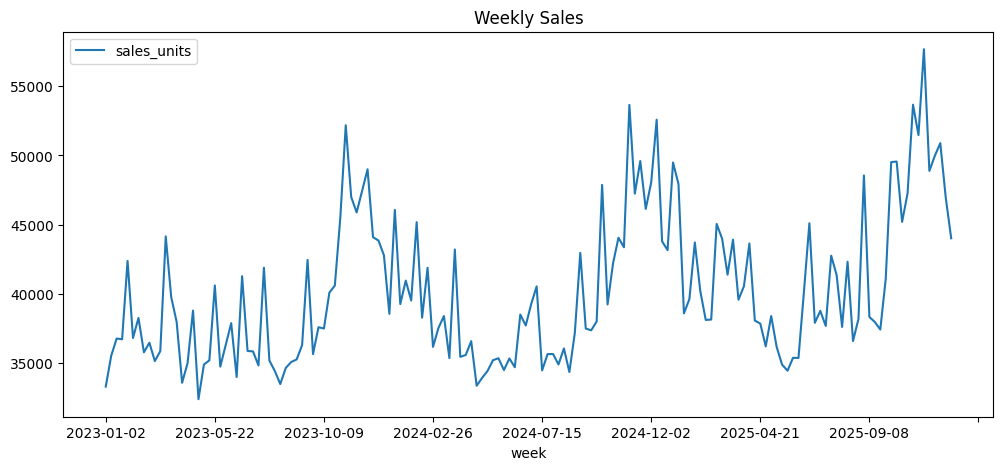

In [0]:
training_df.plot(
    x="week",
    y="sales_units",
    figsize=(12, 5),
    title="Weekly Sales"
);

In [0]:
print("FINAL DATASET INFORMATION")

print(training_df.info())

print("\nDATASET SHAPE:")
print(training_df.shape)

print("\nMISSING VALUES:")
display(training_df.isnull().sum())

print("\nDESCRIPTIVE STATISTICS:")
display(training_df.describe().round(2))

FINAL DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   week         156 non-null    object 
 1   tv           156 non-null    float64
 2   search       156 non-null    float64
 3   social       156 non-null    float64
 4   display      156 non-null    float64
 5   email        156 non-null    float64
 6   price        156 non-null    float64
 7   promo        156 non-null    float64
 8   season_idx   156 non-null    float64
 9   trend        156 non-null    float64
 10  sales_units  156 non-null    int64  
dtypes: float64(9), int64(1), object(1)
memory usage: 13.5+ KB
None

DATASET SHAPE:
(156, 11)

MISSING VALUES:


week           0
tv             0
search         0
social         0
display        0
email          0
price          0
promo          0
season_idx     0
trend          0
sales_units    0
dtype: int64


DESCRIPTIVE STATISTICS:


tv,search,social,display,email,price,promo,season_idx,trend,sales_units
156.0,156.0,156.0,156.0,156.0,156.0,156.0,156.0,156.0,156.0
953.18,540.66,375.04,264.11,95.53,1997.33,0.08,1.08,1.09,40176.6
222.82,173.65,131.36,96.45,41.33,39.16,0.11,0.11,0.05,5263.96
440.2,115.21,70.0,50.0,18.0,1892.09,0.0,1.0,1.0,32387.0
797.11,418.38,285.57,188.61,61.43,1974.05,0.0,1.0,1.04,35828.0
935.8,526.23,385.91,270.88,93.93,1998.19,0.0,1.01,1.09,38399.5
1088.55,647.72,469.39,324.18,122.12,2016.23,0.15,1.11,1.14,43735.25
1568.03,1042.09,681.42,504.86,190.74,2126.15,0.36,1.35,1.18,57680.0
